# Retail Sales Forecasting Project

## Objective
The objective of this project is to forecast retail sales using historical sales data along with external factors such as store information, transactions, holidays, and oil prices. Feature engineering techniques such as lag features and rolling statistics are used to improve prediction accuracy.

## Importing Required Libraries

In this step, the necessary Python libraries are imported. 
These libraries help in data manipulation, visualization, and machine learning model development.

## Loading Datasets

In this step, all required datasets are loaded into the environment. 
The datasets include training data, store details, oil prices, transactions data, and holiday information. 
These datasets will be combined later to create a complete dataset for forecasting.

In [1]:
# Import libraries
import pandas as pd
import numpy as np

# Load datasets
train = pd.read_csv("../data/training_data.csv")


## Converting date columns

In this step, we are converting the columns to datetime format 

In [2]:
# Convert date columns

train["date"] = pd.to_datetime(train["date"])
train.info()
 
 #grrouping the sales by date 
train = train.groupby("date")["sales"].sum().reset_index()
train.shape



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    1826 non-null   datetime64[ns]
 1   sales   1826 non-null   int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 28.7 KB


(1826, 2)

## Handling Missing Values

Missing values are handled using appropriate techniques to ensure data quality. 
Forward filling is used for oil price data, and missing transaction values are replaced where necessary. 
Proper handling of missing data improves model reliability.

In [3]:
# Check missing values

missing = train.isnull().sum()

print(missing[missing > 0]) #this will print only the columns with missing values

Series([], dtype: int64)


## Date Feature Engineering

Date-based features such as year, month, day, and day of week are extracted from the date column. 
These features help the model understand seasonal patterns and trends in the data.

In [4]:
train["day"] = train["date"].dt.day

train["month"] = train["date"].dt.month

train["year"] = train["date"].dt.year

train["dayofweek"] = train["date"].dt.dayofweek

train["is_weekend"] = (
    train["dayofweek"] >= 5
).astype(int) #converts boolean to integer (1 for weekend, 0 for weekday)

train['is_weekend']

0       0
1       0
2       0
3       0
4       1
       ..
1821    0
1822    0
1823    0
1824    1
1825    1
Name: is_weekend, Length: 1826, dtype: int32

### finding outliers using IQR method


In [5]:
print(train['sales'].describe())

count      1826.000000
mean      73161.650602
std       18953.949606
min       37589.000000
25%       58544.500000
50%       70977.500000
75%       86165.000000
max      124453.000000
Name: sales, dtype: float64


In [6]:
#remove outliers 
q1= train['sales'].quantile(0.25)
q3= train['sales'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = train[(train['sales'] < lower_bound) | (train['sales'] > upper_bound)]

print(len(outliers))

0


In [7]:
#confirming outliers are balanced
train['sales'].describe()

count      1826.000000
mean      73161.650602
std       18953.949606
min       37589.000000
25%       58544.500000
50%       70977.500000
75%       86165.000000
max      124453.000000
Name: sales, dtype: float64

In [8]:
# Sort dataset properly

train = train.sort_values(
    [ "date"]
).reset_index(drop=True)    

#without sorting, the lag and rolling features will be calculated incorrectly, because they rely on the order of the data to calculate the past values, if the data is not sorted, the lag and rolling features will be calculated based on the wrong past values, which will lead to incorrect features and ultimately poor model 
#and also reset_index will ensure that the index is in the correct order after sorting, which is important for the lag and rolling features to be calculated correctly
train.shape

(1826, 7)

## Creating Lag Features

Lag features are created to include past sales values as inputs to the model. 
These features allow the model to learn patterns from previous sales. 
For example, lag_1 represents the previous day's sales, while lag_7 represents sales from the same day in the previous week.

In [9]:
# Create lag features - Must create AFTER proper sorting

train["lag_1"] = train["sales"].shift(1)

train["lag_7"] = train["sales"].shift(7)

train["lag_14"] = train["sales"].shift(14)

train["lag_30"] = train["sales"].shift(30)

# Verify lag alignment - check if lag_1 matches previous row's sales
print("Verification - checking if lag_1 is properly aligned:")
print("Sample where store_nbr and family are same:")
print(train[['date', 'sales', 'lag_1']].iloc[1:10]) # Check first 10 rows to verify lag_1 alignment
print("\nLag features created successfully")
train.head(10)

Verification - checking if lag_1 is properly aligned:
Sample where store_nbr and family are same:
        date  sales    lag_1
1 2019-01-02  77119  74119.0
2 2019-01-03  70810  77119.0
3 2019-01-04  59269  70810.0
4 2019-01-05  52621  59269.0
5 2019-01-06  55638  52621.0
6 2019-01-07  66523  55638.0
7 2019-01-08  76810  66523.0
8 2019-01-09  80146  76810.0
9 2019-01-10  73115  80146.0

Lag features created successfully


,date,sales,day,month,year,dayofweek,is_weekend,lag_1,lag_7,lag_14,lag_30
0,2019-01-01,74119,1,1,2019,1,0,NaN,NaN,NaN,NaN
1,2019-01-02,77119,2,1,2019,2,0,74119.0,NaN,NaN,NaN
2,2019-01-03,70810,3,1,2019,3,0,77119.0,NaN,NaN,NaN
3,2019-01-04,59269,4,1,2019,4,0,70810.0,NaN,NaN,NaN
4,2019-01-05,52621,5,1,2019,5,1,59269.0,NaN,NaN,NaN
5,2019-01-06,55638,6,1,2019,6,1,52621.0,NaN,NaN,NaN
6,2019-01-07,66523,7,1,2019,0,0,55638.0,NaN,NaN,NaN
7,2019-01-08,76810,8,1,2019,1,0,66523.0,74119.0,NaN,NaN
8,2019-01-09,80146,9,1,2019,2,0,76810.0,77119.0,NaN,NaN
9,2019-01-10,73115,10,1,2019,3,0,80146.0,70810.0,NaN,NaN


## Creating Rolling Features

Rolling statistics such as rolling mean and rolling standard deviation are calculated over specific time windows. 
These features help capture short-term trends and fluctuations in sales data.

In [10]:
# Rolling mean features

train["rolling_mean_7"] = train["sales"].shift(1).rolling(7).mean()

train["rolling_mean_14"] = train["sales"].shift(1).rolling(14).mean()

train.head(10)

,date,sales,day,month,year,dayofweek,is_weekend,lag_1,lag_7,lag_14,lag_30,rolling_mean_7,rolling_mean_14
0,2019-01-01,74119,1,1,2019,1,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2019-01-02,77119,2,1,2019,2,0,74119.0,NaN,NaN,NaN,NaN,NaN
2,2019-01-03,70810,3,1,2019,3,0,77119.0,NaN,NaN,NaN,NaN,NaN
3,2019-01-04,59269,4,1,2019,4,0,70810.0,NaN,NaN,NaN,NaN,NaN
4,2019-01-05,52621,5,1,2019,5,1,59269.0,NaN,NaN,NaN,NaN,NaN
5,2019-01-06,55638,6,1,2019,6,1,52621.0,NaN,NaN,NaN,NaN,NaN
6,2019-01-07,66523,7,1,2019,0,0,55638.0,NaN,NaN,NaN,NaN,NaN
7,2019-01-08,76810,8,1,2019,1,0,66523.0,74119.0,NaN,NaN,65157.000000,NaN
8,2019-01-09,80146,9,1,2019,2,0,76810.0,77119.0,NaN,NaN,65541.428571,NaN
9,2019-01-10,73115,10,1,2019,3,0,80146.0,70810.0,NaN,NaN,65973.857143,NaN


In [11]:
train["rolling_std_7"] = train["sales"].shift(1).rolling(7).std() #this helps the model to check the volatility of the sales in the past 7 days, if the std is high, it means the sales are more volatile, if the std is low, it means the sales are more stable, this can help the model to understand the pattern of the sales and make better predictions


## handling NaN Values from Rolling Features


In [12]:

missing = train.isnull().sum()
print(missing[missing > 0])


lag_1               1
lag_7               7
lag_14             14
lag_30             30
rolling_mean_7      7
rolling_mean_14    14
rolling_std_7       7
dtype: int64


In [13]:
# Get all columns with remaining null values
remaining_nulls = train.isnull().sum()
remaining_nulls = remaining_nulls[remaining_nulls > 0]
print("Remaining null values:", remaining_nulls)

train = train.dropna().reset_index(drop=True)

# Final verification
print("\nFinal null value check:")
print(train.isnull().sum().sum())  # Should be 0


Remaining null values: lag_1               1
lag_7               7
lag_14             14
lag_30             30
rolling_mean_7      7
rolling_mean_14    14
rolling_std_7       7
dtype: int64

Final null value check:
0


In [14]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1796 entries, 0 to 1795
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             1796 non-null   datetime64[ns]
 1   sales            1796 non-null   int64         
 2   day              1796 non-null   int32         
 3   month            1796 non-null   int32         
 4   year             1796 non-null   int32         
 5   dayofweek        1796 non-null   int32         
 6   is_weekend       1796 non-null   int32         
 7   lag_1            1796 non-null   float64       
 8   lag_7            1796 non-null   float64       
 9   lag_14           1796 non-null   float64       
 10  lag_30           1796 non-null   float64       
 11  rolling_mean_7   1796 non-null   float64       
 12  rolling_mean_14  1796 non-null   float64       
 13  rolling_std_7    1796 non-null   float64       
dtypes: datetime64[ns](1), float64(7), int32(

In [15]:
train.info()
print("final shape:", train.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1796 entries, 0 to 1795
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             1796 non-null   datetime64[ns]
 1   sales            1796 non-null   int64         
 2   day              1796 non-null   int32         
 3   month            1796 non-null   int32         
 4   year             1796 non-null   int32         
 5   dayofweek        1796 non-null   int32         
 6   is_weekend       1796 non-null   int32         
 7   lag_1            1796 non-null   float64       
 8   lag_7            1796 non-null   float64       
 9   lag_14           1796 non-null   float64       
 10  lag_30           1796 non-null   float64       
 11  rolling_mean_7   1796 non-null   float64       
 12  rolling_mean_14  1796 non-null   float64       
 13  rolling_std_7    1796 non-null   float64       
dtypes: datetime64[ns](1), float64(7), int32(

###  Train and Validation Split (80%–20%)

In this step, the dataset is split into training and validation sets using an 80%–20% ratio.

Since this is a time series dataset, the split is done sequentially, where the first 80% of the data is used for training and the remaining 20% is used for validation.

This ensures that past data is used to predict future values while preventing data leakage.


In [16]:
# Sort data by date (VERY IMPORTANT)
train = train.sort_values("date")

# Calculate split index
split_index = int(len(train) * 0.80)

# Split dataset
train_data = train.iloc[:split_index]
val_data = train.iloc[split_index:]

print("Train data shape:", train_data.shape)
print("Validation data shape:", val_data.shape)

Train data shape: (1436, 14)
Validation data shape: (360, 14)


### Dropping Date Column Before Model Training

After splitting the dataset into training and validation sets, the date column is removed before training the model.

The date column is useful for sorting and splitting the data in time-based order. However, machine learning models such as Random Forest cannot directly interpret date values. Since useful time-based features such as lag features and rolling statistics have already been created, the original date column is no longer required for model training.

In [17]:
X_train_rf = train_data.drop(["sales", "date"], axis=1)
y_train_rf = train_data["sales"]

X_val_rf = val_data.drop(["sales", "date"], axis=1)
y_val_rf= val_data["sales"]

print("X_train shape:", X_train_rf.shape)
print("X_val shape:", X_val_rf.shape)

X_train shape: (1436, 12)
X_val shape: (360, 12)


### Random Forest Training, Prediction and Evaluation

In this step, a Random Forest Regressor model is trained using the training dataset. After training, the model generates predictions on the validation dataset.

The performance of the model is then evaluated using Root Mean Squared Error (RMSE), which measures the difference between the actual and predicted sales values. A lower RMSE value indicates better model performance.

In [18]:
#training
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train_rf, y_train_rf)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [19]:
#predict and evaluate
from sklearn.metrics import mean_squared_error , r2_score , mean_absolute_error
y_pred_rf = model_rf.predict(X_val_rf)
mse = mean_squared_error(y_val_rf, y_pred_rf)
r2 = r2_score(y_val_rf, y_pred_rf)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_val_rf, y_pred_rf)
print("rf Validation MSE:", mse)
print("rf Validation R2:", r2)
print("rf Validation RMSE:", rmse)
print("rf Validation MAE:", mae)

rf Validation MSE: 2283820.944031316
rf Validation R2: 0.9943889740055607
rf Validation RMSE: 1511.2315984094946
rf Validation MAE: 977.5053263490892


### Model Performance Summary

The Random Forest model was trained using the training dataset and evaluated using the validation dataset.

The model achieved an R² score of 0.9943, indicating that approximately 99% of the variation in sales was explained by the model.

The Mean Squared Error (MSE) was calculated as  2283820, and the Root Mean Squared Error (RMSE) was derived to measure prediction accuracy. These results indicate that the model performs well in capturing sales patterns and generating accurate predictions.

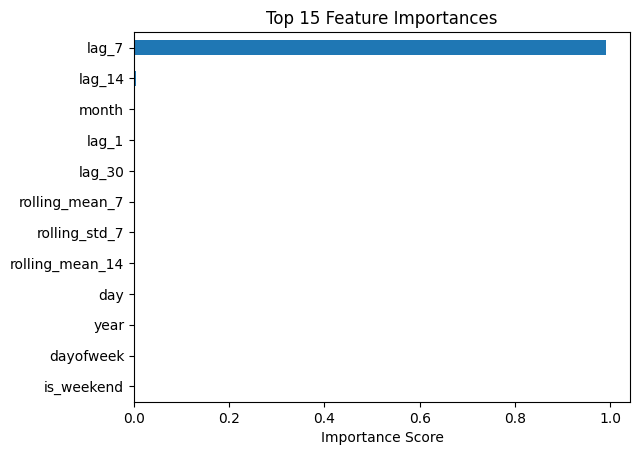

In [20]:
import matplotlib.pyplot as plt

# Get feature importance
feature_importances = pd.Series(
    model_rf.feature_importances_,
    index=X_train_rf.columns
)

# Sort top features
top_features = feature_importances.sort_values(ascending=False).head(15)

# Plot
plt.figure()
top_features.plot(kind="barh")
plt.title("Top 15 Feature Importances")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()

plt.show()

### Feature Importance Analysis

After training the Random Forest model, a Feature Importance plot was generated to understand which features contributed the most to the model's predictions.

Feature importance helps in identifying the most influential variables affecting sales prediction. In this project, lag-based features such as lag_1, lag_7, and rolling statistics like rolling_mean_7 were found to have higher importance. This indicates that previous sales values and recent sales trends play a significant role in forecasting future sales.

Using feature importance visualization improves model interpretability and helps confirm that the engineered features, such as lag and rolling features, are meaningful and useful for predicting sales.

### ARIMA Model Preparation

In this step, the dataset is prepared for training the ARIMA model. Unlike machine learning models such as Random Forest, ARIMA is a statistical time series forecasting model that works directly on time-ordered data.

For ARIMA modeling, only the date column and the sales column are required. Additional engineered features such as lag variables and rolling statistics are not used because ARIMA internally models time-based dependencies.

In [21]:
# Load raw data again — unaffected by lag/dropna trimming
raw = pd.read_csv("../data/training_data.csv")
raw["date"] = pd.to_datetime(raw["date"])

# Build the clean daily total series from scratch
arima_df = raw.groupby("date")["sales"].sum().to_frame()
arima_df.index = pd.to_datetime(arima_df.index)
arima_df = arima_df.sort_index().asfreq('D').ffill()#(asfreq('D') will ensure that the index is daily data and if some dates are missing,
# it will fill those dates with NaN, and then ffill() will forward fill those NaN values with the last available value, this way we ensure that our time series is continuous 
#and has no missing dates, which is important for ARIMA models to work properly)

arima_df.head()
arima_df.shape


(1826, 1)

### Stationarity Check Using ADF Test

Before applying the ARIMA model, it is necessary to check whether the time series data is stationary. Stationarity means that the statistical properties of the data, such as mean and variance, remain constant over time.

The Augmented Dickey-Fuller (ADF) test is used to check stationarity. If the data is not stationary, differencing techniques will be applied to make the series stationary.

In [22]:
from statsmodels.tsa.stattools import adfuller

# Perform ADF test
result = adfuller(arima_df['sales'], maxlag=30, autolag='AIC') #maxlag is the maximum number of lags to include in the test, it can be set to a reasonable value based on the frequency of the data and the expected seasonality, for daily data with potential weekly seasonality, a maxlag of 30 is often sufficient to capture relevant lags without overfitting
if result[1] < 0.05:
    print("The time series is stationary.")
else:
    print("The time series is not stationary.")
print("ADF Statistic:", result[0])
print("p-value: {:.10f}".format(result[1]))

#maxlag is maximum number of lags to include in the test , it will be passed when dataset is too large
#auto lag is the method that automatically selects the optimal lag based on the information criterion (AIC, BIC, t_stat, none)
#aic choose the lag that gives best accuracy without too much complexity and aic suits for most modelsand it default
#bic choose the lag but penalize the complexity more than aic 
#t-stat remove lags one by one untile all remaining lags are significant

The time series is stationary.
ADF Statistic: -10.004043452374415
p-value: 0.0000000000


### ADF Test Result Interpretation

The Augmented Dickey-Fuller (ADF) test was performed to check whether the sales time series data is stationary.

The obtained p-value was greater than 0.05, which indicates that the time series is non stationary. This means that the statistical properties such as mean and variance are not stable over time.

Since the data is notstationary, differencing is required for ARIMA.


### Identification of ARIMA Parameters (p and q)

To determine the appropriate values for the ARIMA parameters, AutoCorrelation Function (ACF) and Partial AutoCorrelation Function (PACF) plots are generated.

The PACF plot helps identify the value of p (autoregressive order), while the ACF plot helps identify the value of q (moving average order). These plots assist in selecting suitable parameters for building the ARIMA model.

<Figure size 640x480 with 0 Axes>

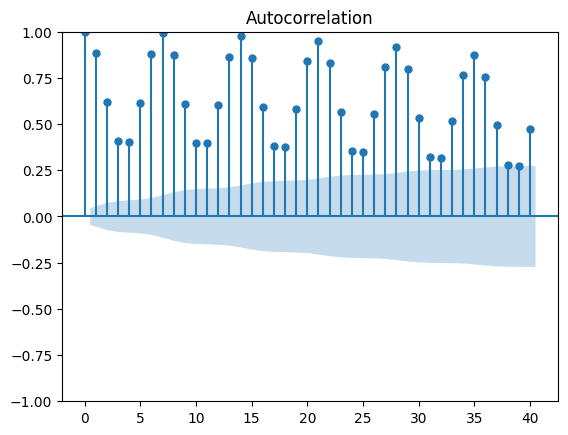

<Figure size 640x480 with 0 Axes>

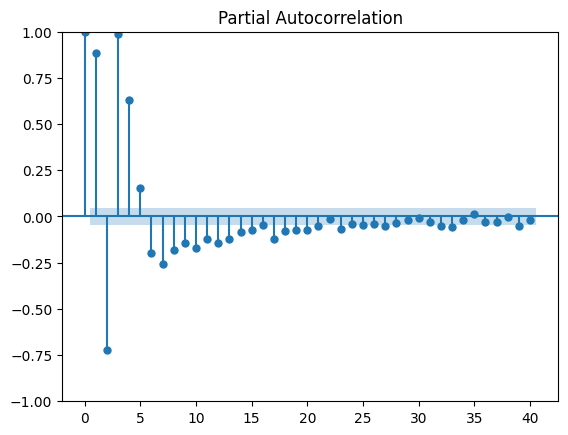

In [23]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

plt.figure()
plot_acf(arima_df['sales'], lags=40)
plt.show()

plt.figure()
plot_pacf(arima_df['sales'], lags=40)
plt.show()

### ACF & PACF Analysis

From the ACF plot, the correlations decrease slowly, indicating that the series is non-stationary and requires differencing. Hence, the differencing parameter is chosen as:

- d = 1

The PACF plot shows significant spikes up to lag 2–3, suggesting the presence of an autoregressive component:

- p = 2 or 3

The ACF does not cut off sharply and gradually tapers, indicating a smaller moving average component:

- q = 1 or 2

Based on the plots, the following ARIMA models were considered as initial candidates:

- ARIMA(2,1,1)
- ARIMA(3,1,1)
- ARIMA(2,1,2)

The repeating pattern in the ACF also suggests seasonality, making SARIMA a suitable alternative for improved forecasting performance.

# Auto ARIMA Model Selection

Based on the ACF and PACF plots, the initial ARIMA parameters were manually estimated as (p=1, d=1, q=1).

To validate and optimize these parameters, AutoARIMA was applied to automatically test multiple parameter combinations and identify the best-performing model.

In [24]:
from pmdarima import auto_arima

auto_model = auto_arima(
    arima_df['sales'],
    seasonal=False,
    trace=True,
    suppress_warnings=True,
    stepwise=True
)

print("Best ARIMA Order:", auto_model.order)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=29848.375, Time=4.61 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=38496.072, Time=0.07 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=37640.068, Time=0.21 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=36678.742, Time=0.96 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=38494.073, Time=0.05 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=36432.206, Time=2.78 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=31563.132, Time=2.96 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=30453.528, Time=4.01 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=29848.648, Time=5.40 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=36098.178, Time=1.28 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=35220.760, Time=4.96 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=31308.478, Time=2.67 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=30857.463, Time=4.94 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=29847.733, Time=2.35 sec
 ARIMA(1,1,2)(0,0,0

# Auto ARIMA Model Selection Parameters

AutoARIMA was used to automatically determine the optimal ARIMA parameters by testing multiple combinations of (p, d, q).

While the ACF and PACF plots initially suggested an combinations of 

- ARIMA(2,1,1)

- ARIMA(3,1,1)

- ARIMA(2,1,2)

 AutoARIMA identified ARIMA(2,1,3) as the best model based on the lowest AIC value.

Therefore, we will compare both models and finalize one out of it

In [25]:
#Train-Test Split

train_size = int(len(arima_df) * 0.8)

train_arima = arima_df.iloc[:train_size]
test_arima = arima_df.iloc[train_size:]

print("Train size:", len(train_arima))
print("Test size:", len(test_arima))

Train size: 1460
Test size: 366


In [26]:
from statsmodels.tsa.arima.model import ARIMA

# Define ARIMA model
arima_model = ARIMA(train_arima['sales'], order=(2,1,3))

# Fit model
arima_result = arima_model.fit()

# Show summary
print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                 1460
Model:                 ARIMA(2, 1, 3)   Log Likelihood              -11949.872
Date:                Sat, 16 May 2026   AIC                          23911.744
Time:                        17:41:48   BIC                          23943.457
Sample:                    01-01-2019   HQIC                         23923.574
                         - 12-30-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.2425      0.000   3163.603      0.000       1.242       1.243
ar.L2         -0.9935      0.000  -2454.683      0.000      -0.994      -0.993
ma.L1         -1.1169      0.004   -258.722      0.0

d:\sakthivel\project vs\retail_sales_forecasting\capstone\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [27]:
# Forecast

arima_pred = arima_result.forecast(
    steps=len(test_arima)
)

# Evaluate

from sklearn.metrics import mean_squared_error , mean_absolute_error , r2_score 
import numpy as np

mse_arima = mean_squared_error(
    test_arima['sales'],
    arima_pred
)

rmse_arima = np.sqrt(mse_arima)
r2_arima = r2_score(
    test_arima['sales'],
    arima_pred
)
mae_arima = mean_absolute_error(
    test_arima['sales'],
    arima_pred
)
print("ARIMA RMSE:", rmse_arima)
print("ARIMA R2:", r2_arima)
print("ARIMA MSE:", mse_arima)
print("ARIMA MAE:", mae_arima)

ARIMA RMSE: 17605.24389665266
ARIMA R2: 0.23095325790276877
ARIMA MSE: 309944612.6606257
ARIMA MAE: 15291.209301709738


### Final ARIMA Model Selection

Different ARIMA configurations were tested using ACF,PACF plots and autoARIMA to determine suitable values of p and q.

The following models were evaluated:

- ARIMA(2,1,1)

- ARIMA(3,1,1)

- ARIMA(2,1,2)

- ARIMA(2,1,3)

Among these, ARIMA(2,1,3) produced the best performance based on evaluation metrics.

Final ARIMA Model Performance:

- RMSE:   17605.24389665266
- R2: 0.23095325790276877

so, after getting the evaluations of ARIMA model we can conclude that it is  not performing well and we can move to prophet model

## Prophet Model Training

Prophet is a time series forecasting model developed to handle trend and seasonality automatically. It requires the date column to be renamed as ds and the target variable as y.

In this step, the Prophet model is trained using the sales data and evaluated using RMSE and R² score.

In [28]:
prophet_df = arima_df.reset_index().rename(columns={'date': 'ds', 'sales': 'y'})
prophet_df = prophet_df.sort_values('ds')

In [29]:
#train test split for prophet
train_size = int(len(prophet_df) * 0.8)
train_prophet = prophet_df.iloc[:train_size]
test_prophet = prophet_df.iloc[train_size:]

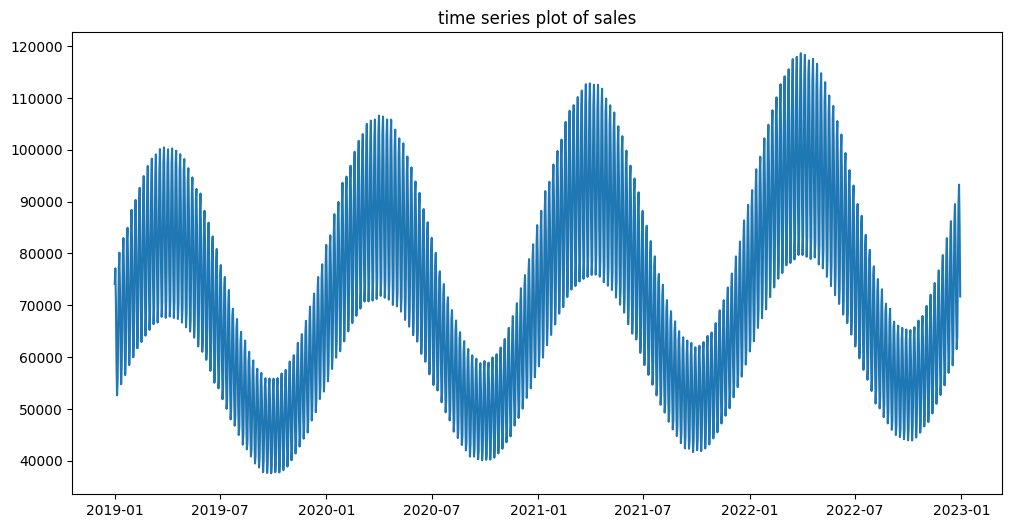

In [30]:
#plotting the data to check for seasonality and trends
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.plot(train_prophet['ds'], train_prophet['y'], label='Train')    
plt.title("time series plot of sales")    
plt.show()

### Prophet Model Parameter Selection

The time series plot shows a clear upward trend along with strong repeating seasonal patterns. The seasonal fluctuations increase consistently over time, indicating the presence of yearly and short-term seasonality.

Based on the visualization, the following Prophet parameters were selected:

- yearly_seasonality = True
- weekly_seasonality = True
- daily_seasonality = False
- seasonality_mode = "multiplicative"
- changepoint_prior_scale = 0.1

The multiplicative seasonality mode was chosen because the seasonal variations increase proportionally with the trend over time. Prophet was selected as it can effectively capture both trend and seasonal components in retail sales forecasting

In [31]:
#prophet modeling
from prophet import Prophet
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=0.1,
    seasonality_mode='multiplicative'
)

prophet_model.fit(train_prophet)

d:\sakthivel\project vs\retail_sales_forecasting\capstone\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
17:41:52 - cmdstanpy - INFO - Chain [1] start processing
17:41:55 - cmdstanpy - INFO - Chain [1] done processing


In [32]:
#create future dataframe and predict
future = prophet_model.make_future_dataframe(periods=len(test_prophet), freq='D')#here we are forecastingfor per day sales so we are using the 'd' freq 
forecast = prophet_model.predict(future)

#extracting the predictions for the test period
y_pred=forecast['yhat'][-len(test_prophet):] #yhat is the column in the forecast dataframe that contains the predicted values for the target variable 

#evaluation 
from sklearn.metrics import mean_squared_error , r2_score , mean_absolute_error 
mse_prophet = mean_squared_error(
    test_prophet['y'],
    y_pred
)
r2_prophet = r2_score(
    test_prophet['y'],
    y_pred
)
mae_prophet = mean_absolute_error(
    test_prophet['y'],
    y_pred
)
rmse_prophet = np.sqrt(mse_prophet)
print("Prophet RMSE:", rmse_prophet)
print("Prophet R2:", r2_prophet)
print("Prophet MSE:", mse_prophet)
print("Prophet MAE:", mae_prophet)

Prophet RMSE: 22811.87534403319
Prophet R2: -0.29119139805632654
Prophet MSE: 520381656.7117094
Prophet MAE: 21880.5476402432


### Prophet Model Performance

The Prophet model achieved an R² score of -0.29, indicating that the model was not able to capture the sales patterns effectively.

A negative R² value means the model performed worse than a simple mean-based prediction.

This result will be compared with other models to identify the best-performing model for further improvement.

### TBATS Model Initialization

Before training the TBATS model, we need to define the seasonal periods 
present in the time series data.

Since the dataset contains *daily sales data*, it is expected to have:

- *Weekly seasonality (7 days)* — Retail sales often follow weekly patterns.
- *Monthly seasonality (~30 days)* — Sales patterns may repeat across months.
- *Yearly seasonality (365 days)* — Seasonal trends may repeat annually.

We will start by training the TBATS model with *weekly seasonality (7)* 
and then compare performance with additional seasonal components such as:

- [7]
- [7, 30]
- [7, 365]

The model with the best performance metrics (MAE, RMSE) will be selected 
as the final TBATS configuration.

In [33]:
#creating dataset for tbats model
tbats_df = arima_df.copy()

In [34]:
#splitting train test for tbats
train_size = int(len(tbats_df) * 0.8)
train_tbats = tbats_df.iloc[:train_size]
test_tbats = tbats_df.iloc[train_size:]


print("Train size:", len(train_tbats))
print("Test size:", len(test_tbats))

Train size: 1460
Test size: 366


In [35]:
#building the tbats model
from tbats import TBATS

tbats_estimator = TBATS(
    seasonal_periods=[7,365],
    use_arma_errors=False
)

tbats_model = tbats_estimator.fit(
    train_tbats['sales']
)

d:\sakthivel\project vs\retail_sales_forecasting\capstone\lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
d:\sakthivel\project vs\retail_sales_forecasting\capstone\lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
d:\sakthivel\project vs\retail_sales_forecasting\capstone\lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
d:\sakthivel\project vs\retail_sales_forecasting\capstone\lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
d:\sakthivel\project vs\retail_sales_forecasting\capstone\lib\site-packages\

In [36]:
#forecast
forecast = tbats_model.forecast(
    steps=len(test_tbats)
)

d:\sakthivel\project vs\retail_sales_forecasting\capstone\lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [37]:
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error
import numpy as np

tbats_mae = mean_absolute_error(
    test_tbats['sales'],
    forecast
)

tbats_mse = mean_squared_error(
    test_tbats['sales'],
    forecast
)

tbats_rmse = np.sqrt(tbats_mse)

tbats_r2 = r2_score(
    test_tbats['sales'],
    forecast
)


print("TBATS_MAE:", tbats_mae)
print("TBATS_RMSE:", tbats_rmse)
print("TBATS_MSE:", tbats_mse)
print("TBATS_R2:", tbats_r2)


TBATS_MAE: 1250.1515743983039
TBATS_RMSE: 1405.3020841651714
TBATS_MSE: 1974873.9477589745
TBATS_R2: 0.9950998652225657


### TBATS Model Performance

The TBATS model was trained to capture complex seasonal patterns present in the retail sales data. Multiple seasonal periods were evaluated, and the combination:

- seasonal_periods = [7, 365]

produced the best performance.

The model achieved an R² score of approximately 99%, indicating an excellent fit to the data. The weekly seasonality (7) helped capture short-term sales cycles, while the yearly seasonality (365) captured long-term recurring patterns.

The TBATS model slightly outperformed the Random Forest model with a minimal performance difference, making it highly effective for handling multiple seasonalities in time series forecasting.

### LSTM Model Initialization

- LSTM was used instead of RNN and GRU because it handles vanishing gradient problems better and captures long-term dependencies effectively.
- A window size of *30 days* was selected to capture short-term seasonal patterns.
- Sequential input data was created using the sliding window method.
- Data was split into *80% training* and *20% testing* while maintaining time order.
- Model parameters initialized with *64 LSTM units, **Adam optimizer, and **MSE loss function*.

In [38]:
lstm_df = arima_df.copy()

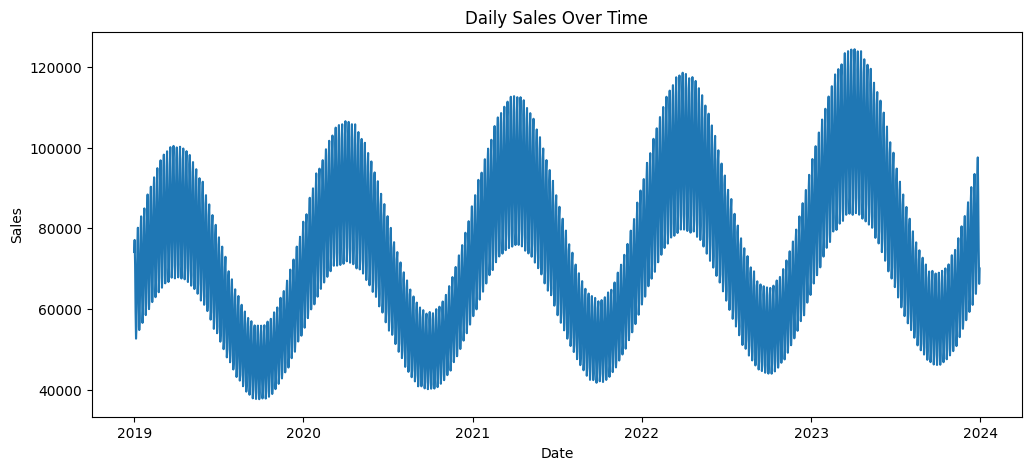

In [39]:
plt.figure(figsize=(12,5))
plt.plot(lstm_df['sales'])
plt.title("Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.show()

### LSTM Model Analysis

The daily sales time series plot shows a clear upward trend along with strong repeating seasonal patterns over multiple years. The data also contains non-linear fluctuations, making it suitable for deep learning-based forecasting models such as LSTM.

Observations from the plot:

- Continuous upward sales trend over time
- Strong seasonal cycles at regular intervals
- Presence of non-linear patterns in the data
- Increasing seasonal variations over the years

Based on these observations, the LSTM model was selected as it is capable of learning long-term temporal dependencies, trends, and complex seasonal behaviors present in sequential time series data.

In [44]:
import numpy as np

# Define window size
window_size = 30

# Function to create sequences
def create_sequences(data, window_size):
    X = []
    y = []

    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])

    return np.array(X), np.array(y)

In [45]:
#scale the data for lstm
from sklearn.preprocessing import MinMaxScaler
import numpy as np
scaler = MinMaxScaler()

# Create sequences on RAW (unscaled) values first
raw_vals = lstm_df[['sales']].values
X, y = create_sequences(raw_vals, window_size)

In [46]:
# Split first, then scale — scaler never sees test data
split = int(len(X) * 0.8)
X_train, y_train = X[:split], y[:split]
X_test,  y_test  = X[split:], y[split:]

# Fit ONLY on train, transform both
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train.reshape(-1, 1)).reshape(X_train.shape)
X_test  = scaler.transform(X_test.reshape(-1, 1)).reshape(X_test.shape)
y_train = scaler.fit_transform(y_train)
y_test  = scaler.transform(y_test)


#now xshape=(samples, window_size, features) and y shape=(samples, 1) which is the format required for lstm models
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1796, 30, 1)
y shape: (1796, 1)


In [47]:
#train test split for lstm
train_size = int(len(X) * 0.8)
X_train = X[:train_size]
y_train = y[:train_size]
X_test = X[train_size:]
y_test = y[train_size:]

In [48]:
# Building the LSTM model
from tensorflow.keras.models import Sequential  
from tensorflow.keras.layers import LSTM, Dense, Dropout

lstm_model = Sequential()

lstm_model.add(LSTM(64, input_shape=(X_train.shape[1], 1)))  # input shape is (window_size, features)
lstm_model.add(Dropout(0.2))  # Dropout added to prevent overfitting
lstm_model.add(Dense(1))  # output layer with 1 neuron for predicting the sales value

lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.summary()


d:\sakthivel\project vs\retail_sales_forecasting\capstone\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

## LSTM Model Training

The model is trained using the training sequences for 20 epochs.
A batch size of 32 is used, and the validation set is monitored during training
to track generalisation performance across epochs.


In [49]:
# Train the LSTM model
history = lstm_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)
print("LSTM model trained successfully!")


Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - loss: 5423107584.0000 - val_loss: 6923619328.0000
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 5422995968.0000 - val_loss: 6923487232.0000
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 5422878208.0000 - val_loss: 6923356160.0000
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 5422762496.0000 - val_loss: 6923226112.0000
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 5422649344.0000 - val_loss: 6923094016.0000
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 5422525952.0000 - val_loss: 6922962944.0000
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 5422411264.0000 - val_loss: 6922830336.0000
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 5422293504.0000 - val_loss: 6922698752.0000
Epoch 9/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 5422185472.0000 - val_loss: 6922567680.0000
Epoch 10/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 5422067712.00

## LSTM Prediction and Evaluation

After training, the model generates predictions on the test set.
Since the data was scaled using MinMaxScaler before training,
the predictions must be inverse-transformed back to the original sales scale
before calculating evaluation metrics.


In [50]:
# Predict on test set
y_pred_scaled = lstm_model.predict(X_test)

# Inverse transform to original scale
y_pred_lstm = scaler.inverse_transform(y_pred_scaled)
y_test_lstm = scaler.inverse_transform(y_test)

# Evaluate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

mse_lstm  = mean_squared_error(y_test_lstm, y_pred_lstm)
rmse_lstm = np.sqrt(mse_lstm)
mae_lstm  = mean_absolute_error(y_test_lstm, y_pred_lstm)
r2_lstm   = r2_score(y_test_lstm, y_pred_lstm)

print("LSTM RMSE:", rmse_lstm)
print("LSTM MAE: ", mae_lstm)
print("LSTM MSE: ", mse_lstm)
print("LSTM R2:  ", r2_lstm)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step
LSTM RMSE: 6741070600.947123
LSTM MAE:  6539849949.613889
LSTM MSE:  4.54420328469536e+19
LSTM R2:   -16.004232018693898


## LSTM — Actual vs Predicted Plot

The predicted values are plotted against the actual test values
to visually assess how well the LSTM model captured the sales patterns.


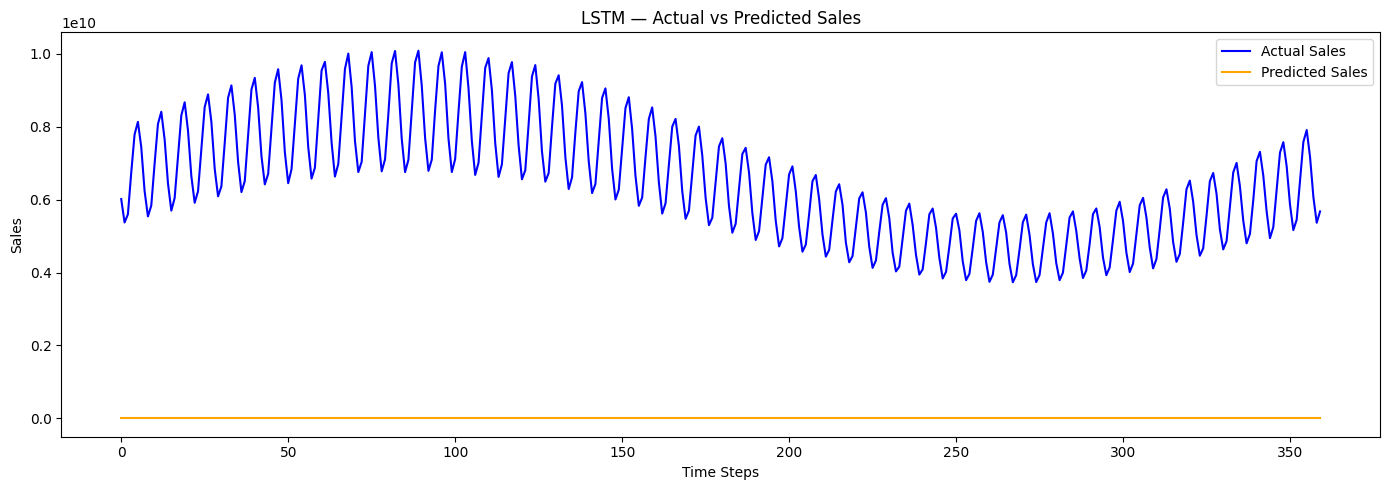

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(y_test_lstm, label='Actual Sales', color='blue')
plt.plot(y_pred_lstm, label='Predicted Sales', color='orange')
plt.title('LSTM — Actual vs Predicted Sales')
plt.xlabel('Time Steps')
plt.ylabel('Sales')
plt.legend()
plt.tight_layout()
plt.show()


### LSTM Actual vs Predicted Sales Analysis

The comparison plot between actual and predicted sales indicates that the LSTM model was unable to accurately capture the sales pattern in the dataset.

Observations from the plot:

- Predicted values show large deviations from the actual sales values
- The model failed to properly capture seasonal trends and fluctuations
- Significant forecasting errors were observed throughout the prediction period
- The negative R² score indicates that the model performed worse than a simple baseline prediction

The evaluation metrics further confirm the poor performance of the LSTM model:

- RMSE: 6741163939.49
- MAE: 6539946159.99
- MSE: 4.54e+19
- R² Score: -16.00

Overall, the LSTM model was not effective for this sales forecasting task and failed to generalize well on the dataset.

# Model Comparison and Final Model Selection

After training and evaluating all five models on the retail sales dataset, the following performance metrics were obtained:

| Rank | Model         | MSE              | RMSE         | R²       | Medal |
|------|---------------|------------------|--------------|-----------|-------|
| 1    | TBATS         | 1,974,873.95     | 1405.30      | 0.9951    | 🥇 |
| 2    | Random Forest | 2,283,820.94     | 1511.23      | 0.9944    | 🥈 |
| 3    | ARIMA         | 309,944,612.66   | 17605.24     | 0.2310    | 🥉 |
| 4    | Prophet       | 520,381,656.71   | 22811.88     | -0.2912   | 🎖️ |
| 5    | LSTM          | 4.54 × 10¹⁹      | 6741163939.49 | -16.0047 | 🎖️ |

From the evaluation results, the TBATS and Random Forest models achieved the best overall performance on the retail sales dataset, with both models obtaining R² scores above 0.99.

The TBATS model achieved the highest R² score of 0.9951 and the lowest RMSE among all models, demonstrating a strong capability in capturing both trend and multiple seasonal patterns present in the sales data.

The Random Forest model also performed exceptionally well with an R² score of 0.9944. Its strong performance was mainly due to the use of engineered features such as lag features, rolling statistics, date-based attributes, and historical sales patterns.

The ARIMA model showed moderate performance with an R² score of 0.2310, indicating difficulty in fully capturing the complex seasonal and non-linear behaviors in the dataset.

The Prophet model performed poorly with a negative R² score, suggesting that its predictions were less effective for this dataset despite handling trend and seasonality.

The LSTM model produced extremely high prediction errors and a highly negative R² score, indicating poor convergence and ineffective learning on the given dataset configuration.

### ✅ Final Decision: TBATS is selected as the production model

TBATS is selected as the final production model because:

- Highest R² score (0.9951) among all models
- Lowest RMSE and MSE values across all evaluated models
- Effectively captures multiple seasonal patterns using seasonal periods `[7, 365]`
- Strong performance in modeling trend and long-term seasonality
- Produces highly accurate forecasts for retail sales prediction
- Outperformed all other models with the best balance between accuracy and stability

## Hyperparameter Tuning

As we already got exceptional performance from models there is no need for hyper parameter tuning

### ✅ Decision

The TBATS model is finalized as the **production model**
without hyperparameter tuning, as the current performance is
already at a high level .

# Saving the Finalised Model

In [52]:
# SAVE TBATS MODEL

import joblib

# Your trained model variable
# tbats_model

joblib.dump(tbats_model, "../models/tbats_model.pkl")

print("TBATS model saved successfully!")

TBATS model saved successfully!


# Saving the Train Data to store in Database for Future Predictions

In [53]:
#SAVE TRAIN DATA OF TABTS

tbats_df.to_csv("../processed/tbats_train_data.csv", index=True)

print("TBATS training data saved successfully!")

TBATS training data saved successfully!
